# Scenario probability distribution



In [5]:
# import relevant packages
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
# Define the time period
start_date = "2006-01-01"
end_date = "2024-09-16"

# downloads the Adjusted Close prices for the VIX, S&P 500 ETF (SPY), and Aggregate Bond ETF (AGG)
tickers = ["^VIX", "SPY", "AGG"]
df_data = yf.download(tickers, start=start_date, end=end_date, auto_adjust=False)['Adj Close']

[*********************100%***********************]  3 of 3 completed


In [ ]:
df_data.head()

Ticker,AGG,SPY,^VIX
Date,,,
2006-01-03,56.682934,89.060509,11.14
2006-01-04,56.818069,89.482307,11.37
2006-01-05,56.818069,89.538513,11.31
2006-01-06,56.688534,90.283630,11.00
2006-01-09,56.750458,90.515602,11.13


## Problem 1

Calculate the log-returns for the for S&P 500 ETF (SPY) and Aggregate Bond ETF (AGG) using the Adj. closing prices. 

In [10]:
"""
Calculate log-returns for SPY and AGG
"""

log_returns = np.log(df_data[['SPY', 'AGG']] / df_data[['SPY', 'AGG']].shift(1)).dropna()

**Tolkning:** We convert the daily closing prices into log-returns, the same way we did back in Week 1 and 2 — this is our standard first step whenever we work with price data.

## Problem 2

Calculate the unconditional covariance and correlation matrix based on the full sample. 

In [11]:
"""
Unconditional covariance and correlation matrix (full sample)
"""

cov_matrix = log_returns.cov()
corr_matrix = log_returns.corr()

print('Unconditional covariance matrix:')
print(cov_matrix)
print('\nUnconditional correlation matrix:')
print(corr_matrix)

Unconditional covariance matrix:
Ticker           SPY           AGG
Ticker                            
SPY     1.508995e-04 -5.816660e-07
AGG    -5.816660e-07  1.146455e-05

Unconditional correlation matrix:
Ticker       SPY       AGG
Ticker                    
SPY     1.000000 -0.013985
AGG    -0.013985  1.000000


**Tolkning:** This treats every single day in our 2006-2024 sample as equally important when measuring how SPY and AGG move together — a financial crisis day counts exactly the same as a calm day.

## Problem 3

Calculate the covariance matrix using scenario probabilities 

$$
p_t \propto \left \{\begin{array}{ll} 1 & \text{if } VIX_t \geq 20 \\ 0 & \text{if } VIX_t < 20 \end{array} \right .
$$

Plot the probabilities over time. 

Use the below function to calculate the probabilities. 

Text(0, 0.5, 'Probability, $p_t$')

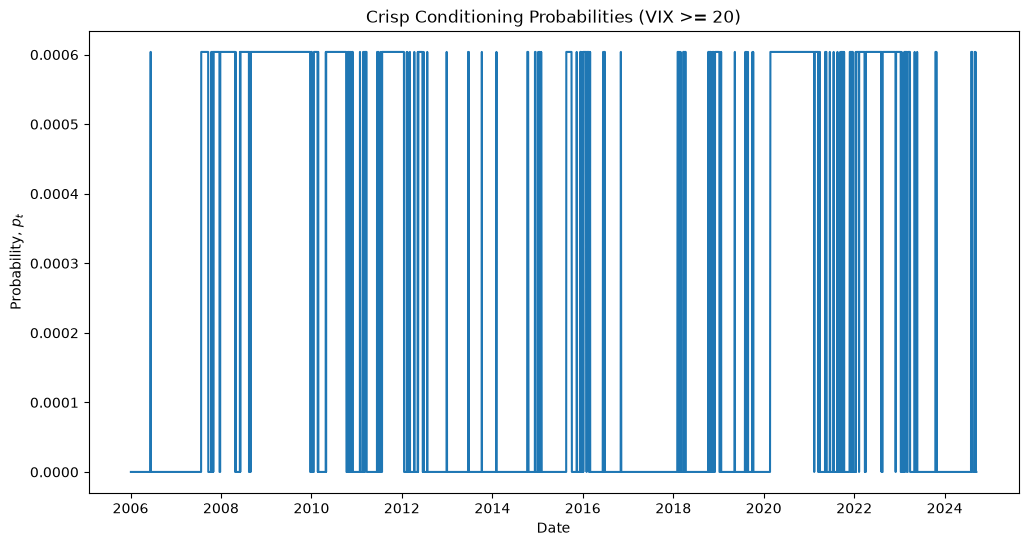

In [15]:
"""
Align VIX with log-returns dates, then calculate crisp conditioning probabilities
"""

vix_aligned = df_data['^VIX'].reindex(log_returns.index)

probs = crisp_conditioning_probs(vix_aligned.values, condition=(20.0, np.inf))

"""
Plot probabilities over time
"""

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(log_returns.index, probs)
ax.set_title('Crisp Conditioning Probabilities (VIX >= 20)')
ax.set_xlabel('Date')
ax.set_ylabel('Probability, $p_t$')

**Tolkning:** Every day gets a "yes" (some equal weight) or "no" (zero weight) based on whether VIX was above 20 that day. The plot should show spikes around known crisis periods (2008 financial crisis, 2020 COVID crash) — those are the days that will now count in our next calculation.

In [14]:
from typing import Tuple 

def crisp_conditioning_probs(x: np.typing.ArrayLike, condition: Tuple = (-np.inf, np.inf)) -> np.ndarray:
    """
    Creates an array of crisp condition probabilities.

    Currently only works for one state variable.

    Parameters
    ----------
    x:
        Array for setting the shape of.
    condition:
        Tuple with lower and upper bound.
    axis:
        The axis to create the weights over. Default is 0.

    Returns
    -------
    ndarray
        Array of equal weights.
    """

    probs = (x >= condition[0]) & (x <= condition[1])
    probs = probs / np.sum(probs)

    return probs


## Problem 5

Calculate the conditional covariance and correlation matrix based on the full sample with the defined probabilities. You may want to use `numpy.cov` which has an argument `aweights` which together with `ddof=0` can be viewed as probabilities.  

In [16]:
"""
Conditional covariance matrix using aweights
"""

cond_cov_matrix = np.cov(log_returns[['SPY', 'AGG']].values, rowvar=False, aweights=probs, ddof=0)

"""
Convert covariance matrix to correlation matrix manually
(np.corrcoef does not support aweights directly)
"""

std_devs = np.sqrt(np.diag(cond_cov_matrix))
cond_corr_matrix = cond_cov_matrix / np.outer(std_devs, std_devs)

print('Conditional covariance matrix (VIX >= 20 periods only):')
print(cond_cov_matrix)
print('\nConditional correlation matrix (VIX >= 20 periods only):')
print(cond_corr_matrix)

Conditional covariance matrix (VIX >= 20 periods only):
[[ 3.42048038e-04 -4.42723809e-07]
 [-4.42723809e-07  2.22032515e-05]]

Conditional correlation matrix (VIX >= 20 periods only):
[[ 1.        -0.0050802]
 [-0.0050802  1.       ]]


**Tolkning:** Both correlations are close to zero, meaning SPY and AGG barely move together in either direction over this period. Interestingly, the correlation during high-VIX (fearful) periods (-0.0051) is not more negative than the overall correlation (-0.0140) — if anything, slightly less negative. This shows that conditioning on a state variable doesn't always confirm the story you'd expect from theory; it's important to actually look at the numbers rather than assume the "textbook" result.

**Key takeaway:** Conditioning on a market state variable (like VIX) lets us test whether a relationship changes under specific conditions — but the actual result won't always match textbook intuition. Here, correlation stayed near zero in both cases. Always let the data speak, rather than assuming a "classic" story before checking.